In [1]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis

  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 543.8/543.8 kB 6.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 545.8/545.8 kB 8.1 MB/s  0:00:00
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 8.1 MB/s  0:00:00 eta 0:00:01
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 976.9/976.9 kB 4.3 MB/s  0:00:00
Using cached pyasn1_modules-0.4.2-py3-none-any.whl (181 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 7.6 MB/s  0:00:01m0:00:0100:01
  Attempting uninstall: re

In [2]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style="html")
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [3]:
plt.rcParams['figure.figsize'] = (12, 6)

In [5]:

catalog_url = (
    "https://storage.googleapis.com/cmip6/pangeo-cmip6.csv"
)

catalog = pd.read_csv(catalog_url, low_memory=False)

print("Total entries:", len(catalog))
display(catalog.head())
print(catalog.columns.tolist())


Total entries: 514818


,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


['activity_id', 'institution_id', 'source_id', 'experiment_id', 'member_id', 'table_id', 'variable_id', 'grid_label', 'zstore', 'dcpp_init_year', 'version']


In [16]:

scenarios = [
    "historical",
    "ssp126",
    "ssp245",
    "ssp370",
    "ssp585"
]

filtered = catalog[
    (catalog["variable_id"] == "tas") &
    (catalog["table_id"] == "Amon") &
    (catalog["experiment_id"].isin(scenarios))
]

print("Matching entries:", len(filtered))

display(
    filtered.groupby("experiment_id")
    .size()
    .rename("count")
)


Matching entries: 2030


experiment_id
historical    635
ssp126        325
ssp245        432
ssp370        312
ssp585        326
Name: count, dtype: int64

In [17]:

subset = filtered[
    filtered["member_id"] == "r1i1p1f1"
]

required = {"historical", "ssp126", "ssp245", "ssp370", "ssp585"}

coverage = subset.groupby(
    ["source_id", "grid_label"]
)["experiment_id"].agg(set)

candidates = coverage[
    coverage.apply(lambda x: required.issubset(x))
]

print("Eligible models:", len(candidates))
display(candidates.head(10))


Eligible models: 27


source_id      grid_label
ACCESS-CM2     gn            {ssp585, ssp370, historical, ssp245, ssp126}
AWI-CM-1-1-MR  gn            {ssp585, ssp370, historical, ssp245, ssp126}
BCC-CSM2-MR    gn            {ssp585, ssp370, historical, ssp245, ssp126}
CAMS-CSM1-0    gn            {ssp585, ssp370, historical, ssp245, ssp126}
CAS-ESM2-0     gn            {ssp585, ssp370, historical, ssp245, ssp126}
CESM2-WACCM    gn            {ssp585, ssp370, historical, ssp245, ssp126}
CMCC-CM2-SR5   gn            {ssp585, ssp370, historical, ssp245, ssp126}
CMCC-ESM2      gn            {ssp585, ssp370, historical, ssp245, ssp126}
CanESM5        gn            {ssp585, ssp370, historical, ssp245, ssp126}
EC-Earth3      gr            {ssp585, ssp370, historical, ssp245, ssp126}
Name: experiment_id, dtype: object

In [18]:

model = "ACCESS-CM2"
grid = "gn"

model_rows = subset[
    (subset["source_id"] == model) &
    (subset["grid_label"] == grid)
]

display(
    model_rows[
        ["source_id", "experiment_id",
         "member_id", "grid_label", "zstore"]
    ]
)


,source_id,experiment_id,member_id,grid_label,zstore
374302,ACCESS-CM2,ssp245,r1i1p1f1,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...
374391,ACCESS-CM2,historical,r1i1p1f1,gn,gs://cmip6/CMIP6/CMIP/CSIRO-ARCCSS/ACCESS-CM2/...
375018,ACCESS-CM2,ssp370,r1i1p1f1,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...
506838,ACCESS-CM2,ssp585,r1i1p1f1,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...
507021,ACCESS-CM2,ssp126,r1i1p1f1,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...


In [19]:

fs = gcsfs.GCSFileSystem(token="anon")

def load_scenario(scenario):
    row = model_rows[
        model_rows["experiment_id"] == scenario
    ].iloc[0]

    mapper = fs.get_mapper(row["zstore"])

    ds = xr.open_zarr(
        mapper,
        consolidated=True
    )

    return ds

historical = load_scenario("historical")
ssp126 = load_scenario("ssp126")
ssp245 = load_scenario("ssp245")
ssp370 = load_scenario("ssp370")
ssp585 = load_scenario("ssp585")

print(ssp245)


/var/folders/d2/jn8131td3f5ddpq2l48z8s6m0000gn/T/ipykernel_36614/119634689.py:10: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_zarr(
/var/folders/d2/jn8131td3f5ddpq2l48z8s6m0000gn/T/ipykernel_36614/119634689.py:10: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_zarr(
/var/folders/d2/jn8131td3f5ddpq2l48z8s6m0000gn/T/ipykernel_36614/119634689.py:10: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a

<xarray.Dataset> Size: 114MB
Dimensions:    (time: 1032, lat: 144, lon: 192, bnds: 2)
Coordinates:
  * time       (time) datetime64[ns] 8kB 2015-01-16T12:00:00 ... 2100-12-16T1...
  * lat        (lat) float64 1kB -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * lon        (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
    lat_bnds   (lat, bnds) float64 2kB ...
    lon_bnds   (lon, bnds) float64 3kB ...
    time_bnds  (time, bnds) datetime64[ns] 17kB ...
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas        (time, lat, lon) float32 114MB ...
Attributes: (12/48)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   60265.0
    branch_time_in_parent:  60265.0
    cmor_version:           3.4.0
    ...                     ...
    table_info:             Creation Date:(30 April 2019) MD5:e14f55f257cceaf...
    title:                  ACCES

/var/folders/d2/jn8131td3f5ddpq2l48z8s6m0000gn/T/ipykernel_36614/119634689.py:10: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_zarr(
/var/folders/d2/jn8131td3f5ddpq2l48z8s6m0000gn/T/ipykernel_36614/119634689.py:10: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_zarr(
/var/folders/d2/jn8131td3f5ddpq2l48z8s6m0000gn/T/ipykernel_36614/119634689.py:10: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a

In [35]:

baseline = historical["tas"].sel(
    time=slice("1995-01-01", "2014-12-31")
).mean("time")

datasets = {
    "SSP1-2.6": ssp126,
    "SSP2-4.5": ssp245,
    "SSP3-7.0": ssp370,
    "SSP5-8.5": ssp585
}

warming_maps = {}
global_series = {}

for name, ds in datasets.items():
    future = ds["tas"].sel(
        time=slice("2041-01-01", "2060-12-31")
    ).mean("time")

    warming_maps[name] = (future - baseline).compute()
    anomaly = ds["tas"] - baseline
    weights = np.cos(np.deg2rad(anomaly["lat"]))
    global_mean = anomaly.weighted(weights).mean(dim=("lat", "lon"))
    global_series[name] = global_mean


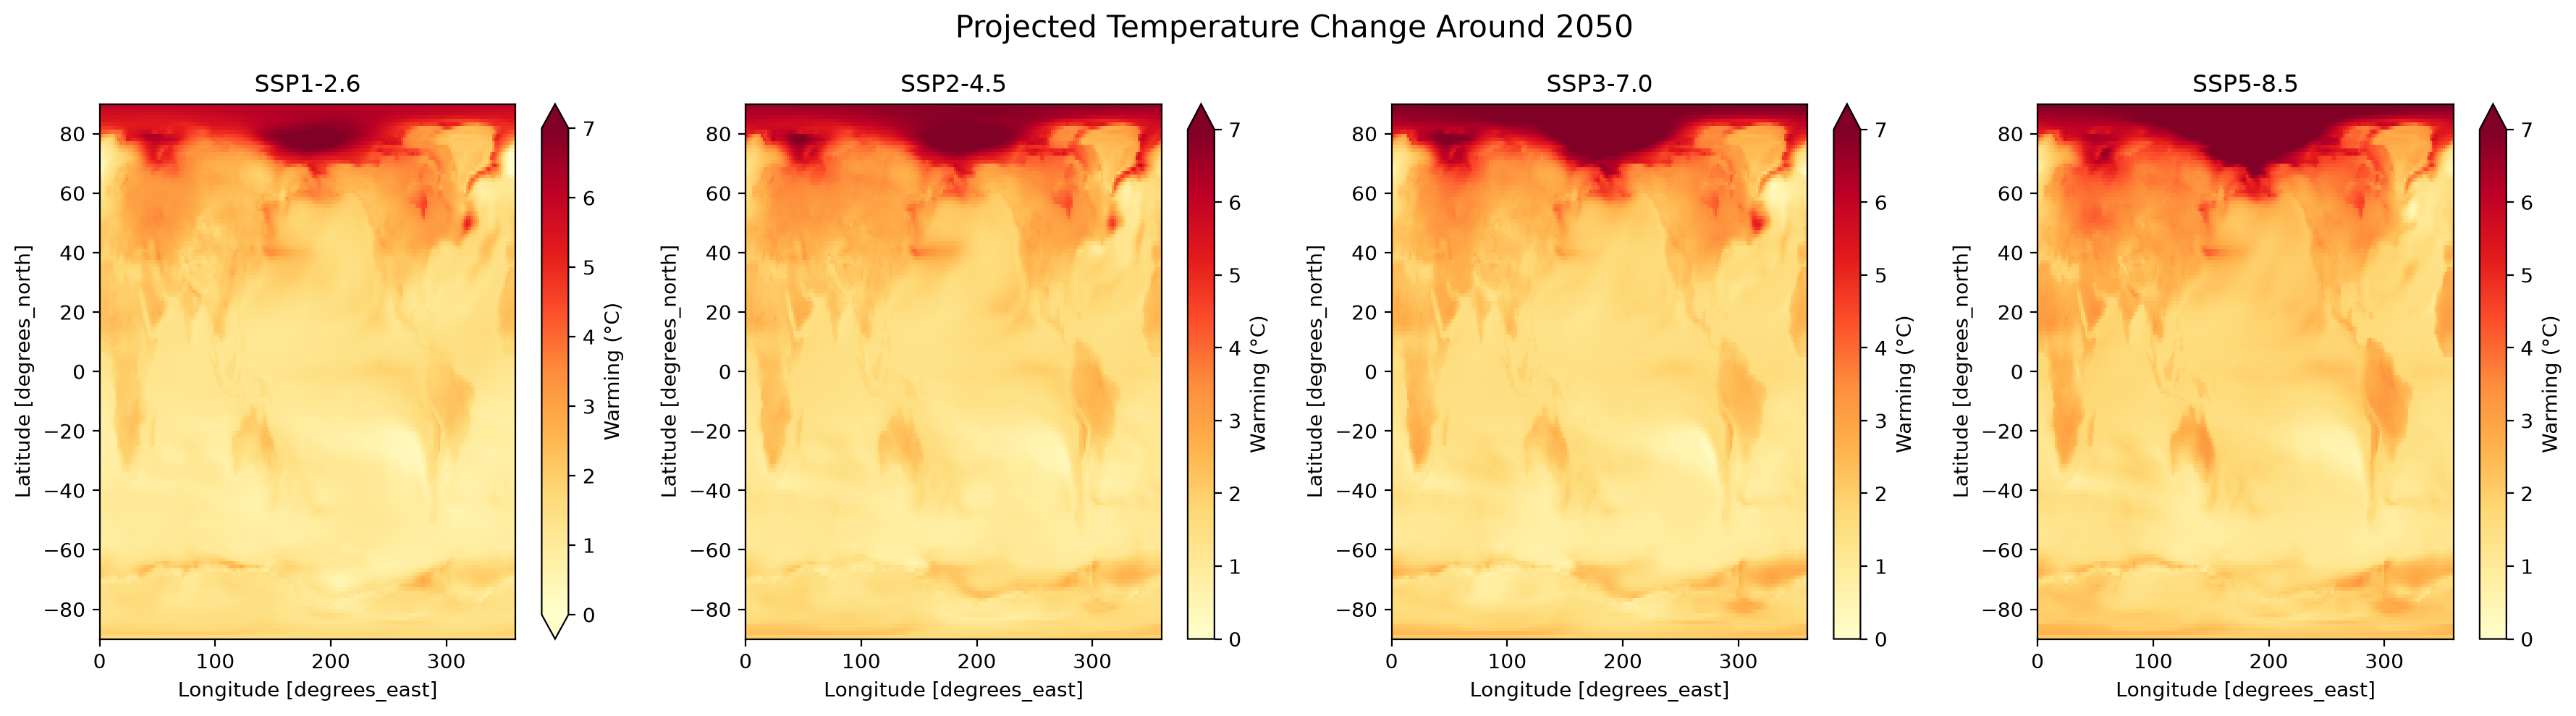

In [24]:

fig, axes = plt.subplots(
    1, 4, figsize=(18, 5)
)

for ax, (name, warming) in zip(
    axes, warming_maps.items()
):
    warming.plot(
        ax=ax,
        vmin=0,
        vmax=7,
        cmap="YlOrRd",
        cbar_kwargs={"label": "Warming (°C)"}
    )
    ax.set_title(name)

plt.suptitle(
    "Projected Temperature Change Around 2050",
    fontsize=15
)
plt.tight_layout()
plt.show()


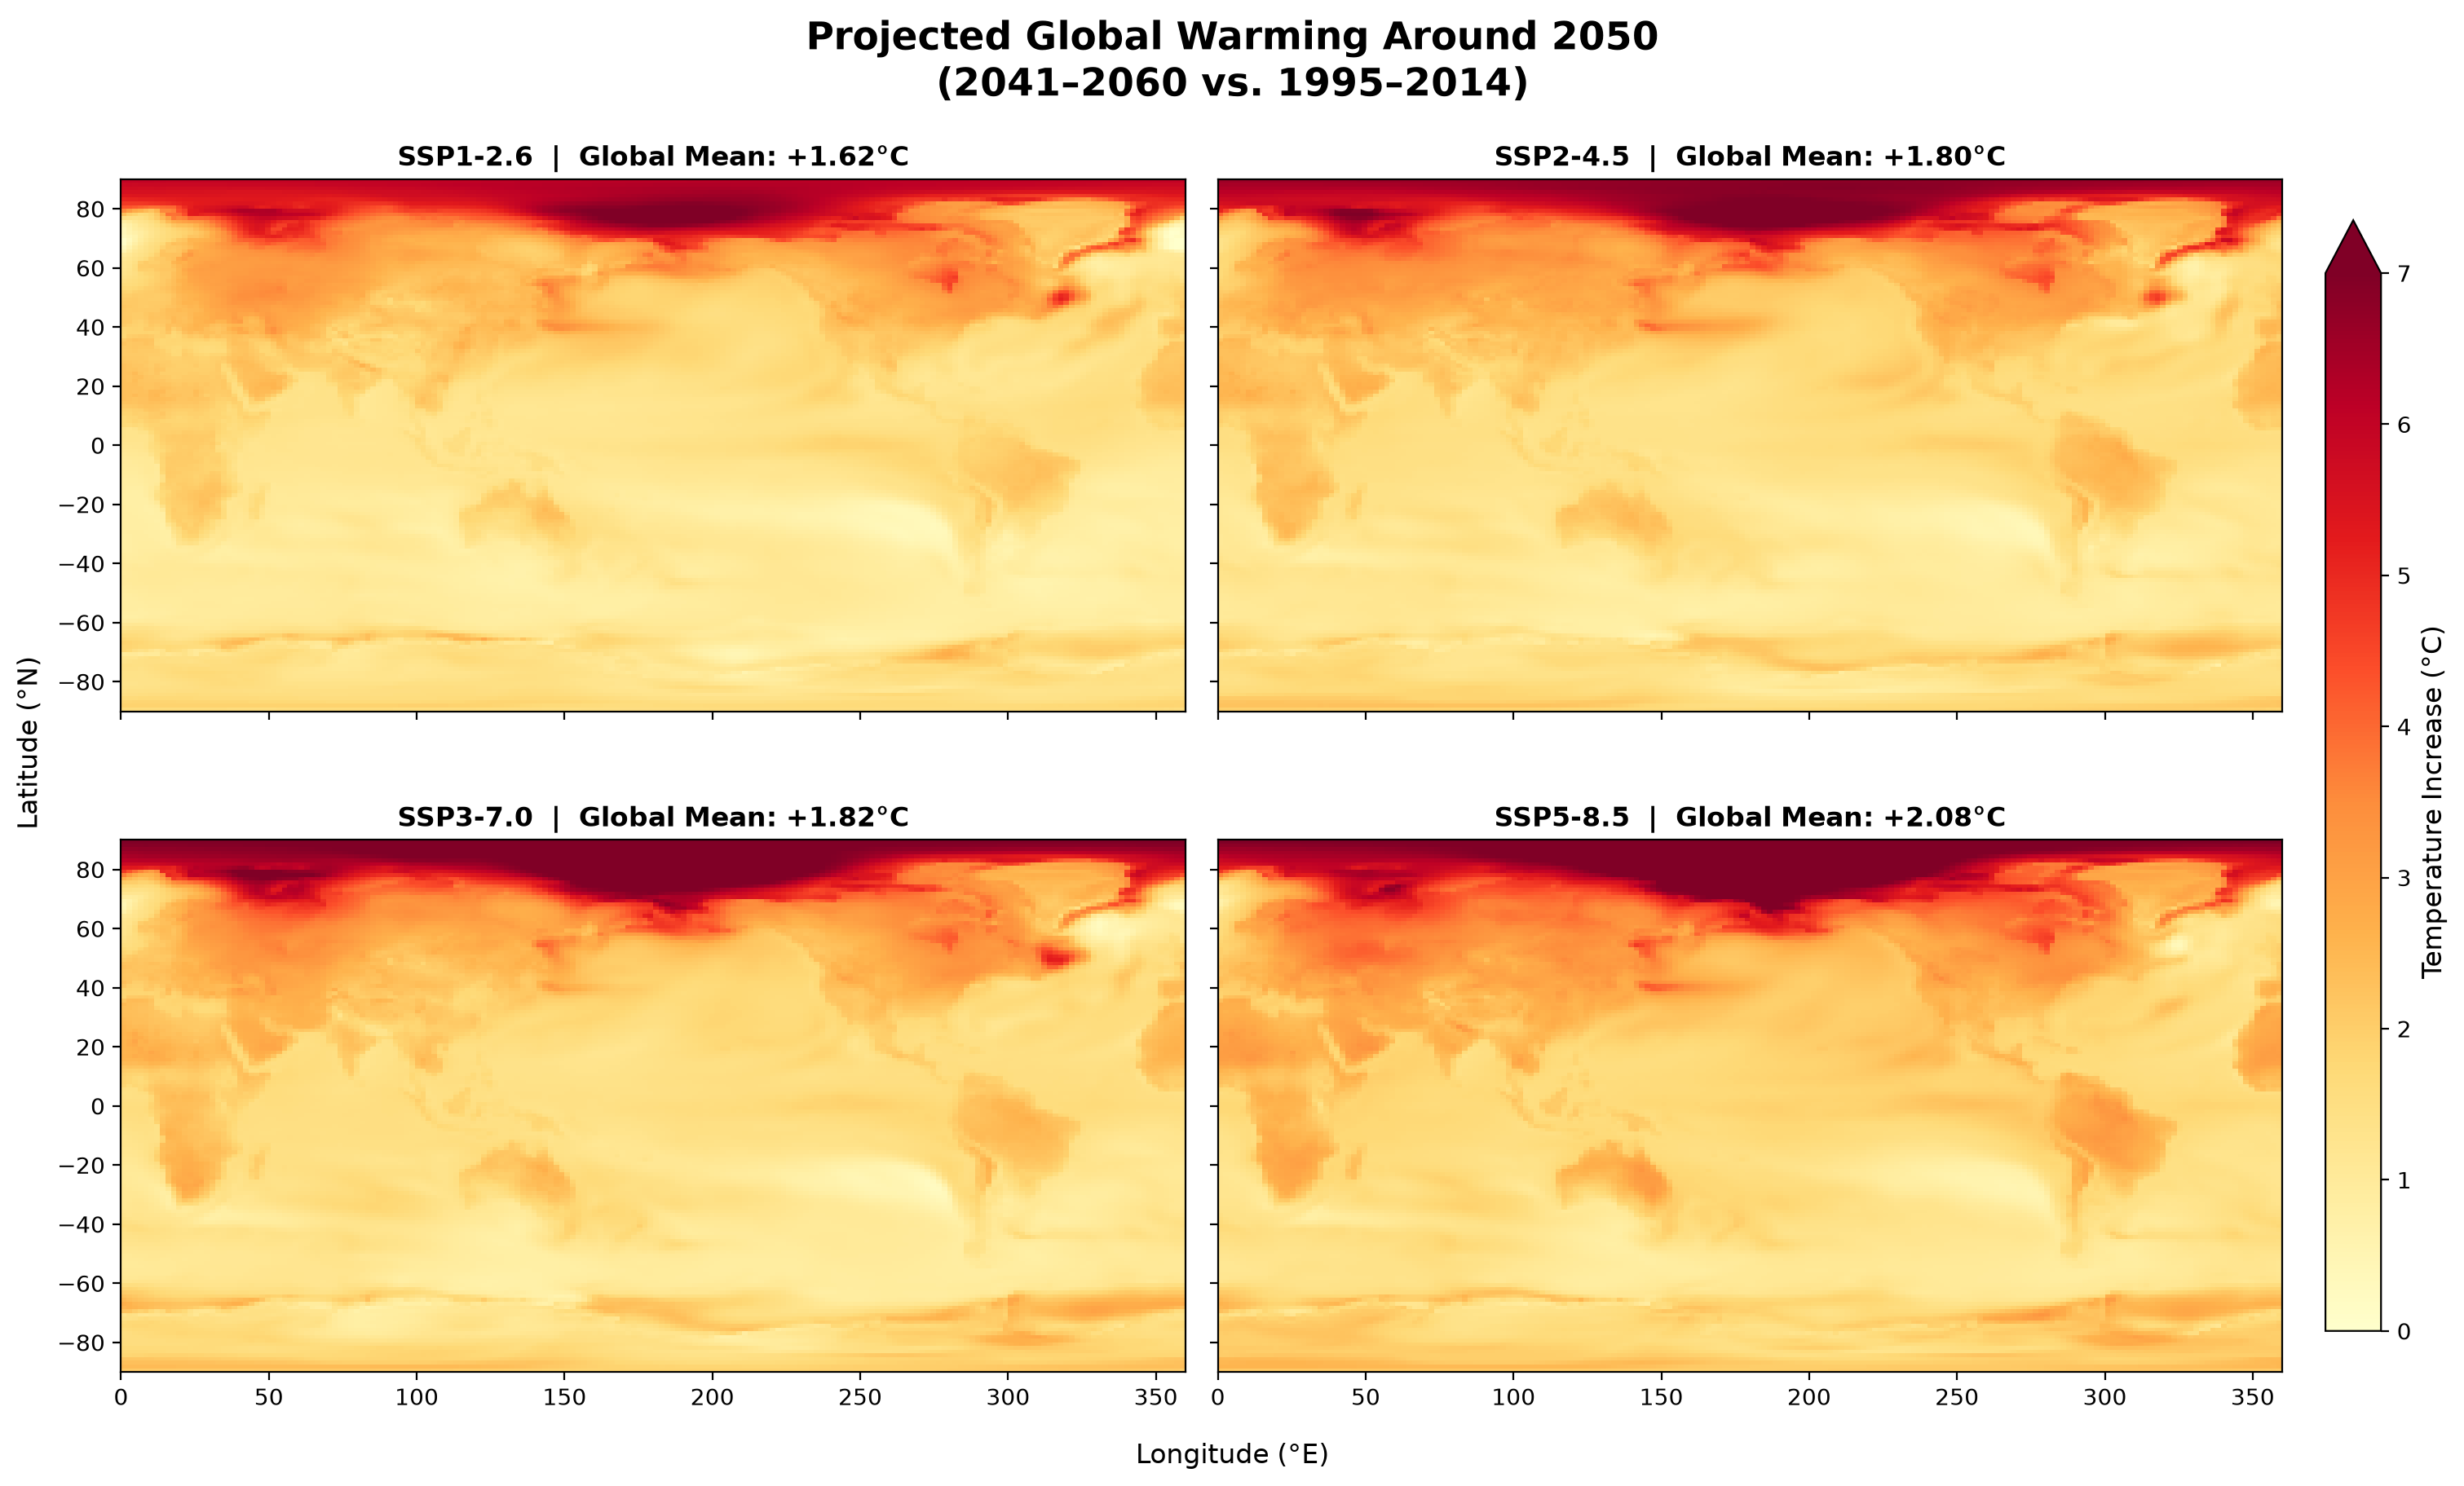

In [25]:
scenario_order = [
    "SSP1-2.6",
    "SSP2-4.5",
    "SSP3-7.0",
    "SSP5-8.5"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, name in zip(axes.flat, scenario_order):
    warming = warming_maps[name]

    # Area-weighted global mean
    weights = np.cos(np.deg2rad(warming["lat"]))
    global_mean = warming.weighted(weights).mean(
        dim=("lat", "lon")
    ).item()

    # Draw map
    im = warming.plot(
        ax=ax,
        x="lon",
        y="lat",
        cmap="YlOrRd",
        vmin=0,
        vmax=7,
        add_colorbar=False
    )

    ax.set_title(
        f"{name}  |  Global Mean: +{global_mean:.2f}°C",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_aspect("equal")
    ax.set_xlim(0, 360)
    ax.set_ylim(-90, 90)
    ax.set_xlabel("")
    ax.set_ylabel("")

# One shared colorbar
cbar = fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.85,
    pad=0.02,
    extend="max"
)

cbar.set_label(
    "Temperature Increase (°C)",
    fontsize=12
)

fig.supxlabel("Longitude (°E)")
fig.supylabel("Latitude (°N)")

fig.suptitle(
    "Projected Global Warming Around 2050\n"
    "(2041–2060 vs. 1995–2014)",
    fontsize=17,
    fontweight="bold"
)

plt.show()


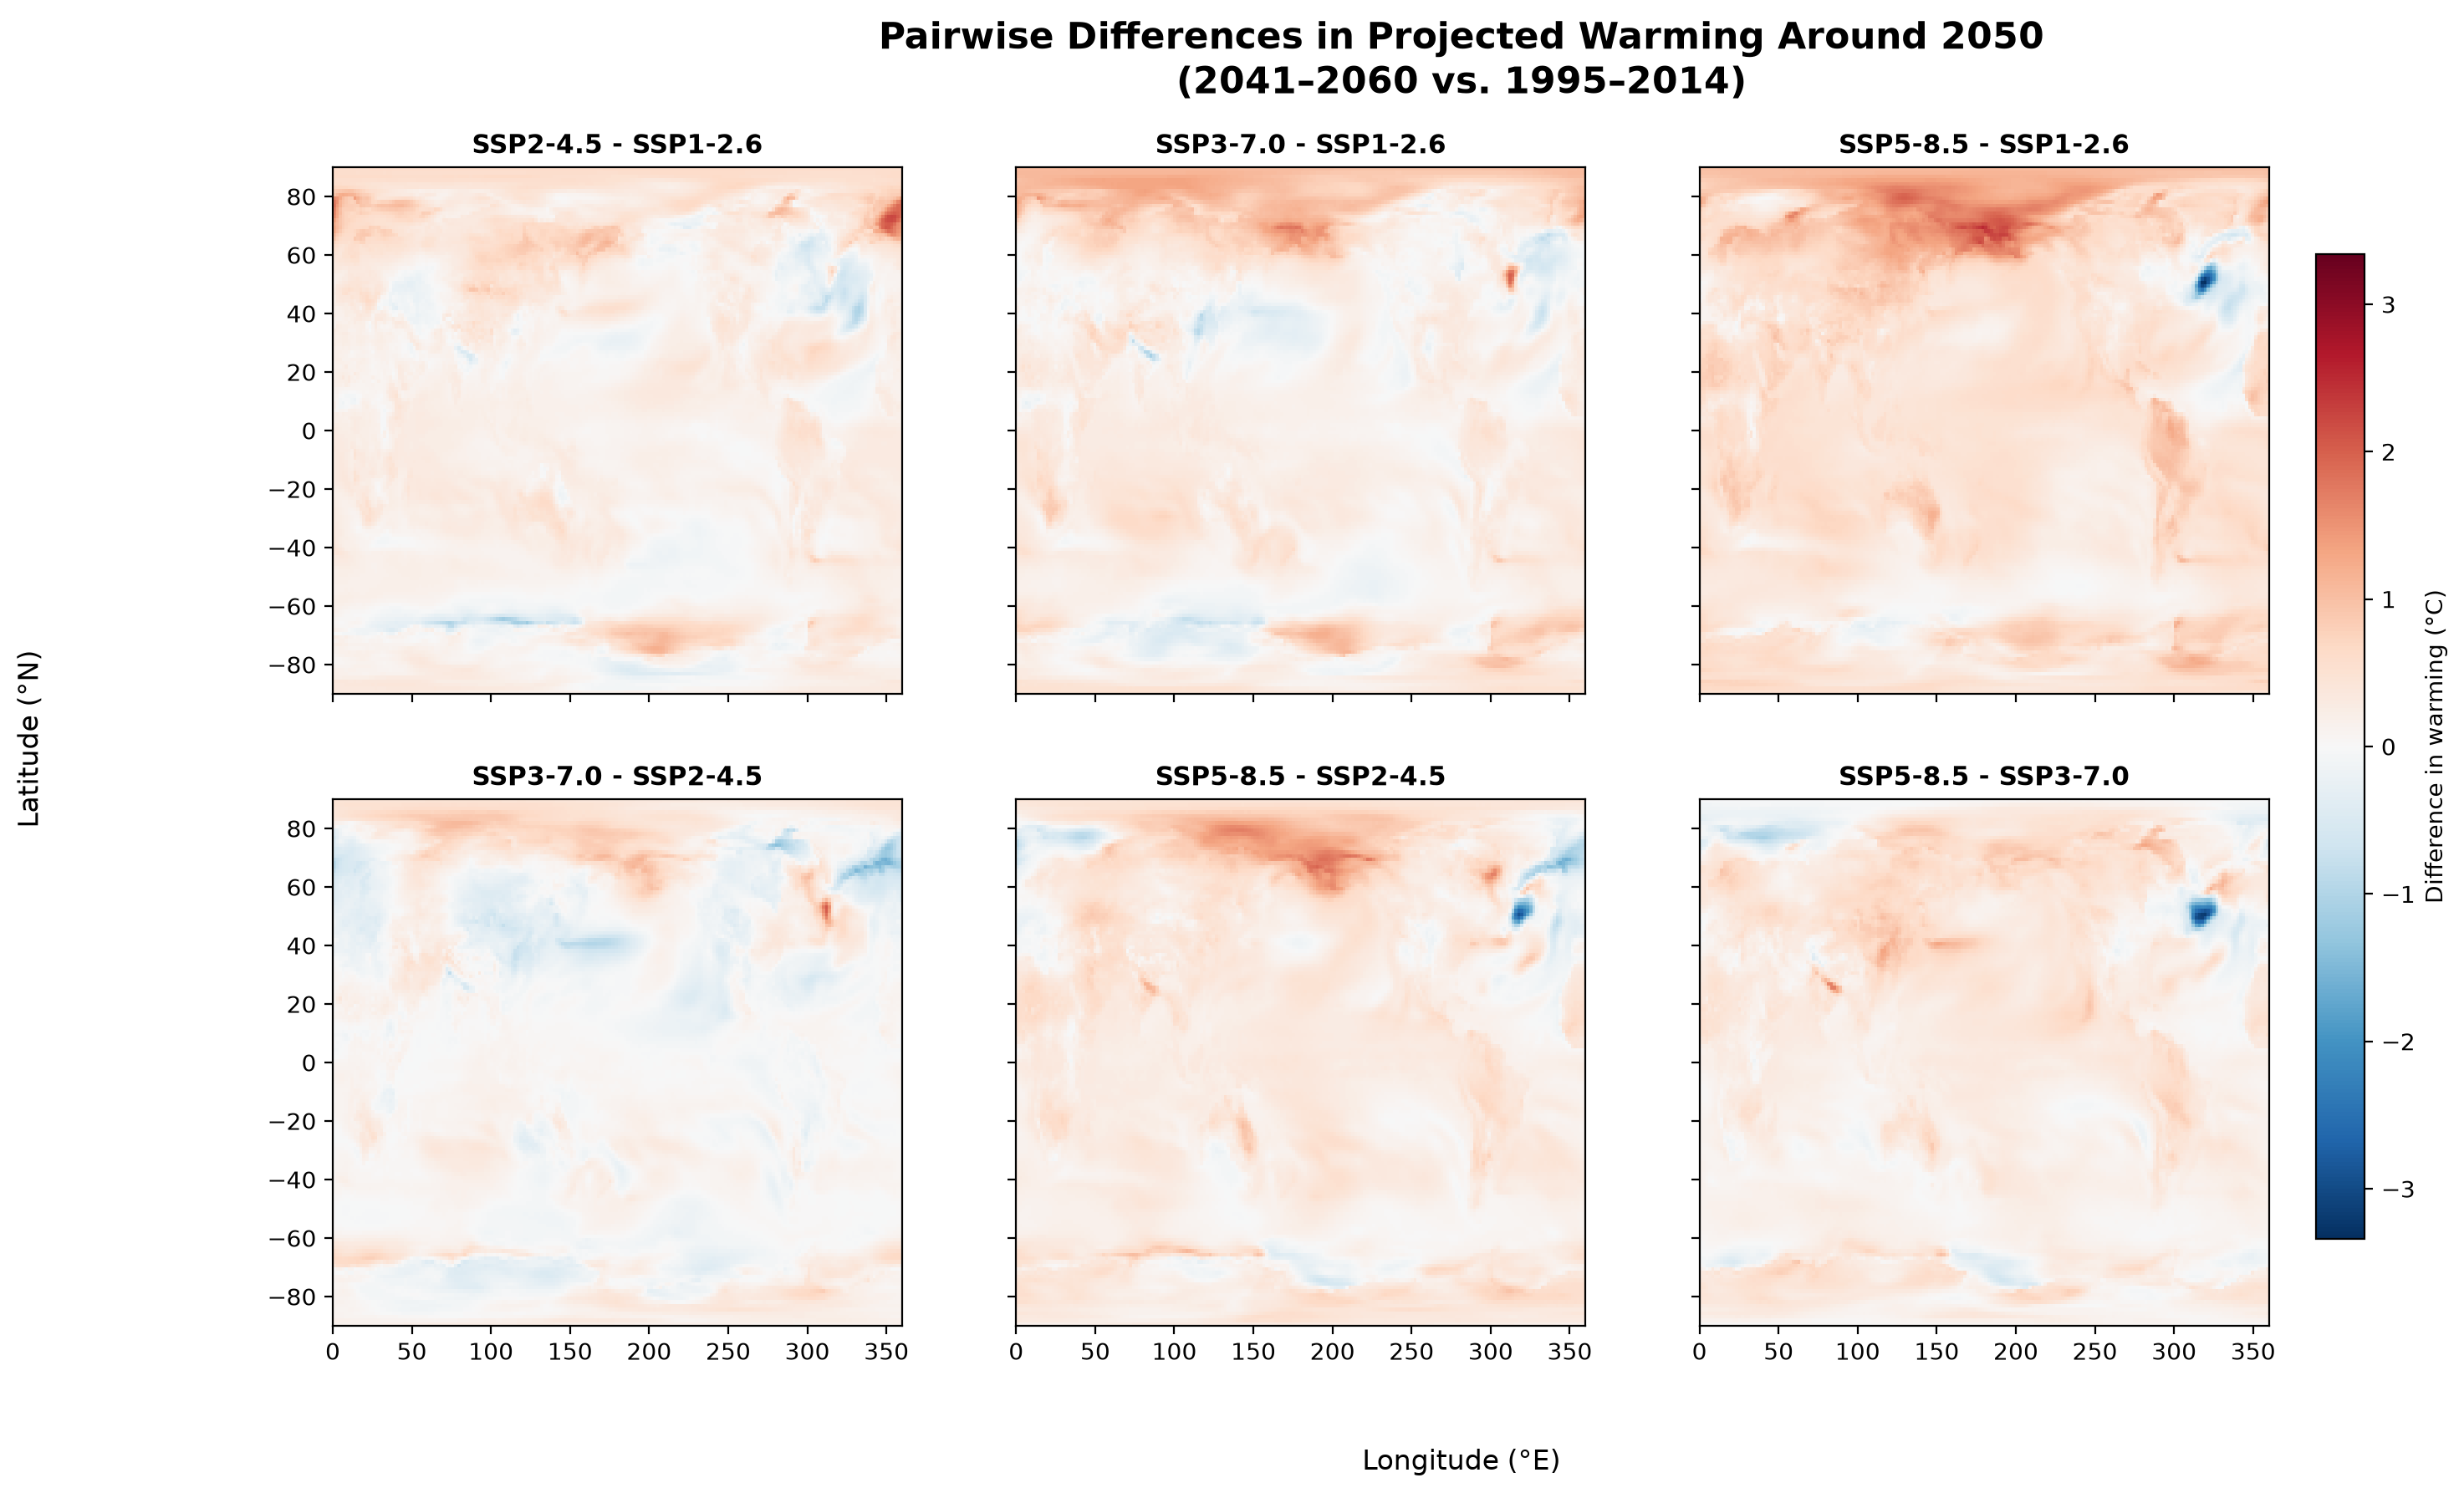

In [ ]:

import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# 1. Prepare all six scenario comparisons
scenario_order = [
    "SSP1-2.6",
    "SSP2-4.5",
    "SSP3-7.0",
    "SSP5-8.5"
]

pairs = list(itertools.combinations(scenario_order, 2))

diff_maps = {
    f"{b} − {a}": warming_maps[b] - warming_maps[a]
    for a, b in pairs
}

# 2. Consistent, symmetric color scale
all_values = np.concatenate([
    diff.values.ravel()
    for diff in diff_maps.values()
])

# 99th percentile improves contrast.
# Values outside this range are clipped visually.
limit = max(
    0.5,
    np.ceil(
        np.nanpercentile(np.abs(all_values), 99) * 2
    ) / 2
)

norm = TwoSlopeNorm(
    vmin=-limit,
    vcenter=0,
    vmax=limit
)

# 3. Create the figure
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8),
    sharex=True,
    sharey=True
)

# Reserve room for title and shared colorbar
fig.subplots_adjust(
    left=0.07,
    right=0.86,
    bottom=0.12,
    top=0.82,
    wspace=0.15,
    hspace=0.32
)

# 4. Draw maps
for i, (ax, (label, diff)) in enumerate(
    zip(axes.flat, diff_maps.items())
):
    im = diff.plot(
        ax=ax,
        x="lon",
        y="lat",
        cmap="RdBu_r",
        norm=norm,
        add_colorbar=False,
        add_labels=False
    )

    ax.set_title(
        label,
        fontsize=11,
        fontweight="semibold",
        pad=10
    )

    ax.set_xlim(0, 360)
    ax.set_ylim(-90, 90)
    ax.set_box_aspect(0.5)

    ax.set_xticks([0, 90, 180, 270, 360])
    ax.set_yticks([-90, -45, 0, 45, 90])

    ax.grid(
        color="gray",
        linestyle="--",
        linewidth=0.4,
        alpha=0.25
    )

    ax.tick_params(
        axis="both",
        labelsize=9,
        length=3
    )

    # Only bottom row shows longitude labels
    if i < 3:
        ax.tick_params(labelbottom=False)

    # Only left column shows latitude labels
    if i % 3 != 0:
        ax.tick_params(labelleft=False)

# 5. Shared colorbar on right
cax = fig.add_axes([0.89, 0.23, 0.018, 0.47])

cbar = fig.colorbar(
    im,
    cax=cax,
    extend="both"
)

cbar.set_label(
    "Difference in Warming (°C)",
    fontsize=11,
    labelpad=10
)

cbar.ax.tick_params(labelsize=9)

# 6. Centered title and subtitle
fig.suptitle(
    "Pairwise Differences in Projected Global Warming",
    x=0.5,
    y=0.97,
    ha="center",
    fontsize=19,
    fontweight="bold"
)

fig.text(
    0.5,
    0.915,
    "2041–2060 vs. 1995–2014 | CMIP6 Climate Projections",
    ha="center",
    fontsize=11,
    color="dimgray"
)

# 7. Shared axis labels
fig.supxlabel(
    "Longitude (°E)",
    fontsize=11,
    y=0.06
)

fig.supylabel(
    "Latitude (°N)",
    fontsize=11,
    x=0.025
)

# Optional explanatory footer
fig.text(
    0.5,
    0.025,
    "Red = greater warming in the higher-emissions scenario"
    "   |   Blue = less warming",
    ha="center",
    fontsize=10,
    color="dimgray"
)

# 8. Save high-resolution image
plt.savefig(
    "pairwise_warming_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


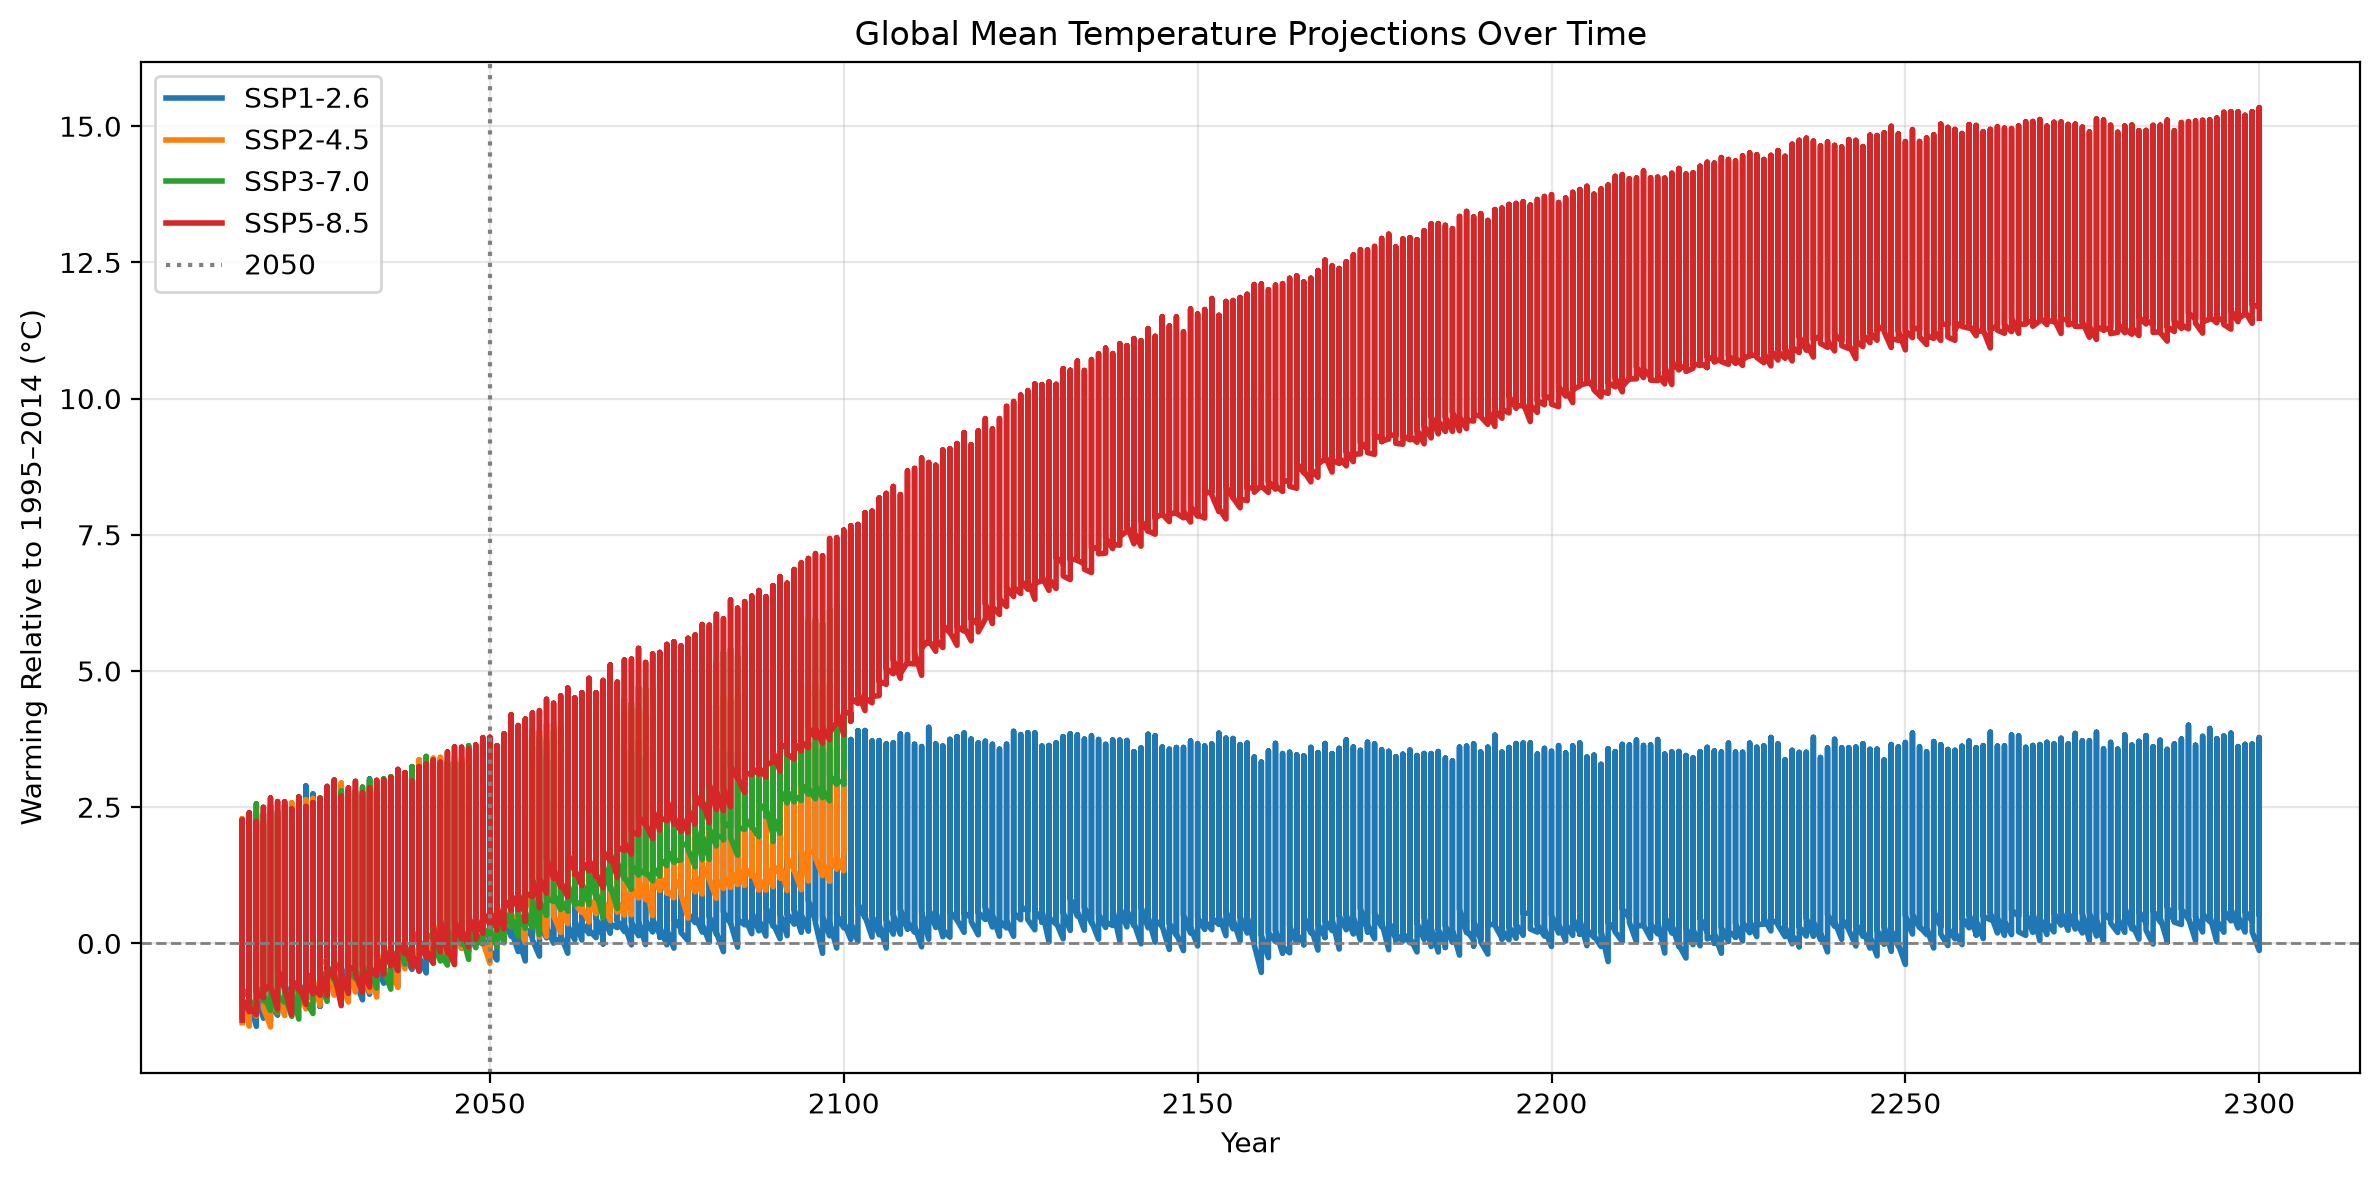

In [37]:

plt.figure(figsize=(12, 6))

for name in scenario_order:
    series = global_series[name]

    # Convert climate dates to numeric years
    years = series["time"].dt.year.values

    plt.plot(
        years,
        series.values,
        label=name,
        linewidth=2
    )

plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvline(2050, color="gray", linestyle=":", label="2050")

plt.title("Global Mean Temperature Projections Over Time")
plt.xlabel("Year")
plt.ylabel("Warming Relative to 1995–2014 (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:
print(global_series.keys())
print(scenario_order)

dict_keys([])
['SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']


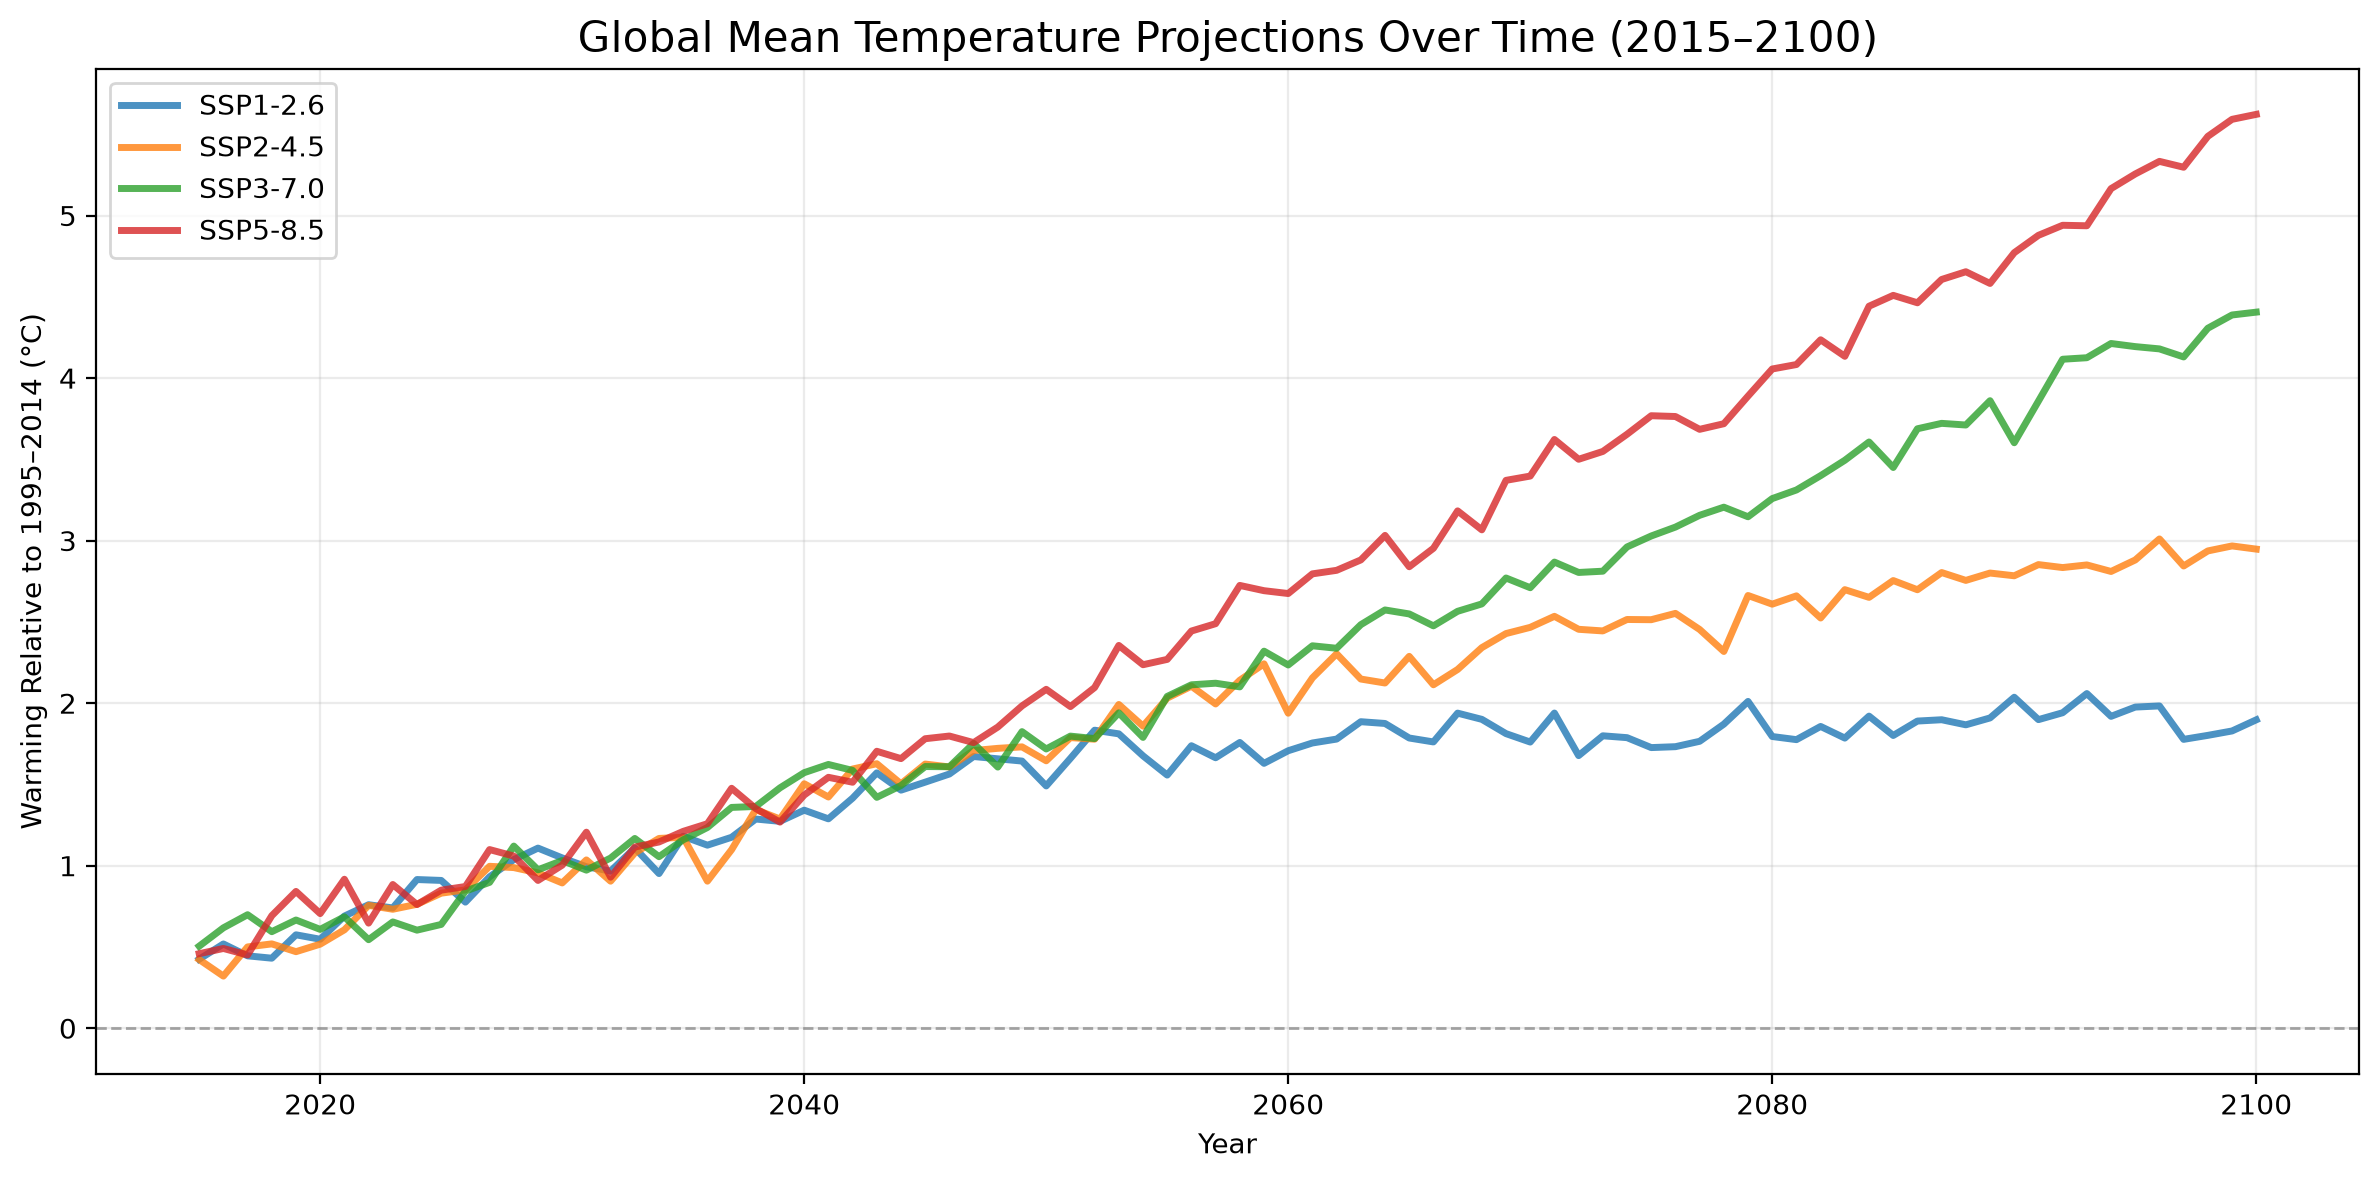

In [41]:
plt.figure(figsize=(12, 6))

for name in scenario_order:
    series = global_series[name]

    years = series["year"].values
    values = series.values

    mask = (years >= 2015) & (years <= 2100)

    plt.plot(
        years[mask],
        values[mask],
        label=name,
        linewidth=2.5,
        alpha=0.8
    )

plt.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.7)

plt.title("Global Mean Temperature Projections Over Time (2015–2100)", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Warming Relative to 1995–2014 (°C)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:

import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# 1. Prepare all six scenario comparisons
scenario_order = [
    "SSP1-2.6",
    "SSP2-4.5",
    "SSP3-7.0",
    "SSP5-8.5"
]

pairs = list(itertools.combinations(scenario_order, 2))

diff_maps = {
    f"{b} − {a}": warming_maps[b] - warming_maps[a]
    for a, b in pairs
}

# 2. Consistent, symmetric color scale
all_values = np.concatenate([
    diff.values.ravel()
    for diff in diff_maps.values()
])

# 99th percentile improves contrast.
# Values outside this range are clipped visually.
limit = max(
    0.5,
    np.ceil(
        np.nanpercentile(np.abs(all_values), 99) * 2
    ) / 2
)

norm = TwoSlopeNorm(
    vmin=-limit,
    vcenter=0,
    vmax=limit
)

# 3. Create the figure
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8),
    sharex=True,
    sharey=True
)

# Reserve room for title and shared colorbar
fig.subplots_adjust(
    left=0.07,
    right=0.86,
    bottom=0.12,
    top=0.82,
    wspace=0.15,
    hspace=0.32
)

# 4. Draw maps
for i, (ax, (label, diff)) in enumerate(
    zip(axes.flat, diff_maps.items())
):
    im = diff.plot(
        ax=ax,
        x="lon",
        y="lat",
        cmap="RdBu_r",
        norm=norm,
        add_colorbar=False,
        add_labels=False
    )

    ax.set_title(
        label,
        fontsize=11,
        fontweight="semibold",
        pad=10
    )

    ax.set_xlim(0, 360)
    ax.set_ylim(-90, 90)
    ax.set_box_aspect(0.5)

    ax.set_xticks([0, 90, 180, 270, 360])
    ax.set_yticks([-90, -45, 0, 45, 90])

    ax.grid(
        color="gray",
        linestyle="--",
        linewidth=0.4,
        alpha=0.25
    )

    ax.tick_params(
        axis="both",
        labelsize=9,
        length=3
    )

    # Only bottom row shows longitude labels
    if i < 3:
        ax.tick_params(labelbottom=False)

    # Only left column shows latitude labels
    if i % 3 != 0:
        ax.tick_params(labelleft=False)

# 5. Shared colorbar on right
cax = fig.add_axes([0.89, 0.23, 0.018, 0.47])

cbar = fig.colorbar(
    im,
    cax=cax,
    extend="both"
)

cbar.set_label(
    "Difference in Warming (°C)",
    fontsize=11,
    labelpad=10
)

cbar.ax.tick_params(labelsize=9)

# 6. Centered title and subtitle
fig.suptitle(
    "Pairwise Differences in Projected Global Warming",
    x=0.5,
    y=0.97,
    ha="center",
    fontsize=19,
    fontweight="bold"
)

fig.text(
    0.5,
    0.915,
    "2041–2060 vs. 1995–2014 | CMIP6 Climate Projections",
    ha="center",
    fontsize=11,
    color="dimgray"
)

# 7. Shared axis labels
fig.supxlabel(
    "Longitude (°E)",
    fontsize=11,
    y=0.06
)

fig.supylabel(
    "Latitude (°N)",
    fontsize=11,
    x=0.025
)

# Optional explanatory footer
fig.text(
    0.5,
    0.025,
    "Red = greater warming in the higher-emissions scenario"
    "   |   Blue = less warming",
    ha="center",
    fontsize=10,
    color="dimgray"
)

# 8. Save high-resolution image
plt.savefig(
    "pairwise_warming_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
